In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import nltk
import re
df=pd.read_csv("Emotion_classify_Data.csv",header=None,encoding='ISO-8859-1')
df

,0,1
0,Comment,Emotion
1,i seriously hate one subject to death but now ...,fear
2,im so full of life i feel appalled,anger
3,i sit here to write i start to dig out my feel...,fear
4,ive been really angry with r and i feel like a...,joy
...,...,...
5933,i begun to feel distressed for you,fear
5934,i left feeling annoyed and angry thinking that...,anger
5935,i were to ever get married i d have everything...,joy
5936,i feel reluctant in applying there because i w...,fear


In [35]:
df.shape

(5938, 2)

In [36]:
df.head()

,0,1
0,Comment,Emotion
1,i seriously hate one subject to death but now ...,fear
2,im so full of life i feel appalled,anger
3,i sit here to write i start to dig out my feel...,fear
4,ive been really angry with r and i feel like a...,joy


In [37]:
df.tail()

,0,1
5933,i begun to feel distressed for you,fear
5934,i left feeling annoyed and angry thinking that...,anger
5935,i were to ever get married i d have everything...,joy
5936,i feel reluctant in applying there because i w...,fear
5937,i just wanted to apologize to you because i fe...,anger


In [38]:
df.isnull().sum()

0    0
1    0
dtype: int64

In [39]:
df.columns=['text','emotion']
df

,text,emotion
0,Comment,Emotion
1,i seriously hate one subject to death but now ...,fear
2,im so full of life i feel appalled,anger
3,i sit here to write i start to dig out my feel...,fear
4,ive been really angry with r and i feel like a...,joy
...,...,...
5933,i begun to feel distressed for you,fear
5934,i left feeling annoyed and angry thinking that...,anger
5935,i were to ever get married i d have everything...,joy
5936,i feel reluctant in applying there because i w...,fear


In [40]:
df.columns

Index(['text', 'emotion'], dtype='object')

In [41]:
df.dtypes

text       object
emotion    object
dtype: object

In [42]:
df1=df['text'].value_counts()
df1

text
i feel like a tortured artist when i talk to her                                                                                                                                                                          2
i resorted to yesterday the post peak day of illness when i was still housebound but feeling agitated and peckish for brew a href http pics                                                                               2
i feel pretty tortured because i work a job and often the inspiration strikes while im at work                                                                                                                            2
im still waiting for my new fairy lights to be delivered but i couldnt wait to get the tree up and make the house feel a little more festive                                                                              1
i set out on foot i feel comparatively strong light and free                                                       

In [43]:
df2=df['emotion'].value_counts()
df2

emotion
anger      2000
joy        2000
fear       1937
Emotion       1
Name: count, dtype: int64

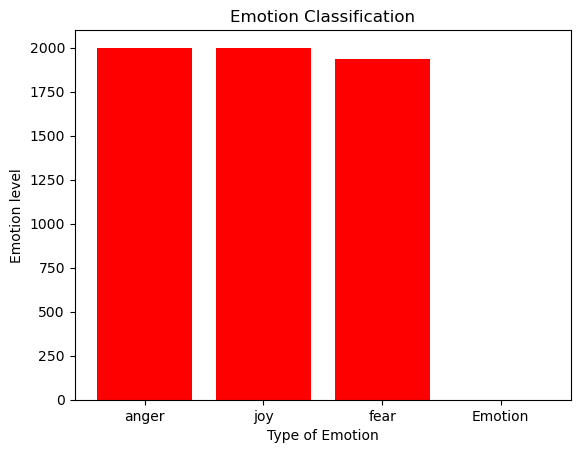

In [44]:
plt.bar(df2.index,df2.values,color="red")
plt.xlabel("Type of Emotion")
plt.ylabel('Emotion level')
plt.title('Emotion Classification')
plt.show()

In [45]:
df.drop(df.index[(df['emotion']=='Emotion')],axis=0,inplace=True)
df

,text,emotion
1,i seriously hate one subject to death but now ...,fear
2,im so full of life i feel appalled,anger
3,i sit here to write i start to dig out my feel...,fear
4,ive been really angry with r and i feel like a...,joy
5,i feel suspicious if there is no one outside l...,fear
...,...,...
5933,i begun to feel distressed for you,fear
5934,i left feeling annoyed and angry thinking that...,anger
5935,i were to ever get married i d have everything...,joy
5936,i feel reluctant in applying there because i w...,fear


In [46]:
df.reset_index(drop=True,inplace=True)
df

,text,emotion
0,i seriously hate one subject to death but now ...,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feel...,fear
3,ive been really angry with r and i feel like a...,joy
4,i feel suspicious if there is no one outside l...,fear
...,...,...
5932,i begun to feel distressed for you,fear
5933,i left feeling annoyed and angry thinking that...,anger
5934,i were to ever get married i d have everything...,joy
5935,i feel reluctant in applying there because i w...,fear


In [47]:
df['emotion']=df['emotion'].map({'fear':0,'anger':-1,'joy':1})
df

,text,emotion
0,i seriously hate one subject to death but now ...,0
1,im so full of life i feel appalled,-1
2,i sit here to write i start to dig out my feel...,0
3,ive been really angry with r and i feel like a...,1
4,i feel suspicious if there is no one outside l...,0
...,...,...
5932,i begun to feel distressed for you,0
5933,i left feeling annoyed and angry thinking that...,-1
5934,i were to ever get married i d have everything...,1
5935,i feel reluctant in applying there because i w...,0


In [48]:
df.dtypes

text       object
emotion     int64
dtype: object

In [49]:
text1=df.text
text1

0       i seriously hate one subject to death but now ...
1                      im so full of life i feel appalled
2       i sit here to write i start to dig out my feel...
3       ive been really angry with r and i feel like a...
4       i feel suspicious if there is no one outside l...
                              ...                        
5932                   i begun to feel distressed for you
5933    i left feeling annoyed and angry thinking that...
5934    i were to ever get married i d have everything...
5935    i feel reluctant in applying there because i w...
5936    i just wanted to apologize to you because i fe...
Name: text, Length: 5937, dtype: object

In [50]:
nltk.download('stopwords')
nltk.download('punkt_tab')


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [51]:
from nltk.tokenize import TweetTokenizer
data=TweetTokenizer()
text1=text1.apply(lambda x:data.tokenize(x)).apply(lambda x:' '.join(x))
text1

0       i seriously hate one subject to death but now ...
1                      im so full of life i feel appalled
2       i sit here to write i start to dig out my feel...
3       ive been really angry with r and i feel like a...
4       i feel suspicious if there is no one outside l...
                              ...                        
5932                   i begun to feel distressed for you
5933    i left feeling annoyed and angry thinking that...
5934    i were to ever get married i d have everything...
5935    i feel reluctant in applying there because i w...
5936    i just wanted to apologize to you because i fe...
Name: text, Length: 5937, dtype: object

In [52]:
text1=text1.replace('[^a-zA-Z0-9]',' ',regex=True)
text1

0       i seriously hate one subject to death but now ...
1                      im so full of life i feel appalled
2       i sit here to write i start to dig out my feel...
3       ive been really angry with r and i feel like a...
4       i feel suspicious if there is no one outside l...
                              ...                        
5932                   i begun to feel distressed for you
5933    i left feeling annoyed and angry thinking that...
5934    i were to ever get married i d have everything...
5935    i feel reluctant in applying there because i w...
5936    i just wanted to apologize to you because i fe...
Name: text, Length: 5937, dtype: object

In [53]:
from nltk.stem import SnowballStemmer
stemer=SnowballStemmer('english')
text1=text1.apply(lambda x:[stemer.stem(i.lower())for i in data.tokenize(x)]).apply(lambda x: ' '.join(x))
text1

0       i serious hate one subject to death but now i ...
1                         im so full of life i feel appal
2       i sit here to write i start to dig out my feel...
3       ive been realli angri with r and i feel like a...
4       i feel suspici if there is no one outsid like ...
                              ...                        
5932                     i begun to feel distress for you
5933    i left feel annoy and angri think that i was t...
5934    i were to ever get marri i d have everyth read...
5935    i feel reluct in appli there becaus i want to ...
5936    i just want to apolog to you becaus i feel lik...
Name: text, Length: 5937, dtype: object

In [54]:
from nltk.corpus import stopwords
words=stopwords.words('english')
text1=text1.apply(lambda x:[i for i in data.tokenize(x) if i not in words]).apply(lambda x:' '.join(x))
text1

0         serious hate one subject death feel reluct drop
1                                 im full life feel appal
2       sit write start dig feel think afraid accept p...
3       ive realli angri r feel like idiot trust first...
4       feel suspici one outsid like raptur happen someth
                              ...                        
5932                                  begun feel distress
5933       left feel annoy angri think center stupid joke
5934    ever get marri everyth readi offer becaus got ...
5935    feel reluct appli becaus want abl find compani...
5936         want apolog becaus feel like heartless bitch
Name: text, Length: 5937, dtype: object

In [55]:
from sklearn.feature_extraction.text import TfidfVectorizer
vec=TfidfVectorizer()
data=vec.fit_transform(text1)
print(data)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 54532 stored elements and shape (5937, 6231)>
  Coords	Values
  (0, 4748)	0.3924297485187133
  (0, 2458)	0.29248647578357173
  (0, 3775)	0.26141211626069766
  (0, 5235)	0.4451952347765912
  (0, 1317)	0.43420650932123844
  (0, 1961)	0.06171955131947581
  (0, 4436)	0.33620763506591916
  (0, 1606)	0.43420650932123844
  (1, 1961)	0.09181039302397886
  (1, 2676)	0.2659637380752031
  (1, 2174)	0.5731955986176726
  (1, 3145)	0.4061472599180497
  (1, 261)	0.6537012702666528
  (2, 1961)	0.05839319785621638
  (2, 4874)	0.3282976807622391
  (2, 6155)	0.28604357777911876
  (2, 5138)	0.25799078720365554
  (2, 1448)	0.4607268115268175
  (2, 5466)	0.23454510010769763
  (2, 100)	0.3055508325481411
  (2, 30)	0.3250383459859768
  (2, 4105)	0.3481591157665799
  (2, 3417)	0.3209635533048003
  (2, 3276)	0.22339759099383713
  (3, 1961)	0.06830980864130878
  :	:
  (5934, 3314)	0.2829665961662456
  (5934, 953)	0.24491671410394486
  (5934, 4345)	0.2

In [56]:
y=df['emotion'].values
y

array([ 0, -1,  0, ...,  1,  0, -1], shape=(5937,))

In [57]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(data,y,test_size=0.30,random_state=42)

In [58]:
x_train

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 38085 stored elements and shape (4155, 6231)>

In [59]:
x_test

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16447 stored elements and shape (1782, 6231)>

In [60]:
y_train

array([-1,  0,  0, ..., -1,  0,  0], shape=(4155,))

In [61]:
y_test

array([-1,  1,  0, ..., -1, -1, -1], shape=(1782,))

In [62]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train,y_train)
y_pred=knn.predict(x_test)
y_pred

array([-1,  1,  0, ..., -1, -1, -1], shape=(1782,))

In [63]:
from sklearn.metrics import accuracy_score
score=accuracy_score(y_test,y_pred)
score

0.7985409652076318

In [64]:
from sklearn.naive_bayes import MultinomialNB
mm=MultinomialNB()
mm.fit(x_train,y_train)
y_pred1=mm.predict(x_test)
y_pred1

array([-1,  1,  0, ..., -1, -1, -1], shape=(1782,))

In [65]:
from sklearn.metrics import accuracy_score
score1=accuracy_score(y_test,y_pred1)
score1

0.8928170594837261

In [66]:
from sklearn.svm import SVC
sv=SVC()
sv.fit(x_train,y_train)
y_pred2=sv.predict(x_test)
y_pred2

array([-1,  1,  0, ..., -1, -1, -1], shape=(1782,))

In [67]:
from sklearn.metrics import accuracy_score
score2=accuracy_score(y_test,y_pred2)
score2

0.9130190796857464

In [68]:
from sklearn.tree import DecisionTreeClassifier
dc=DecisionTreeClassifier(criterion='entropy')
dc.fit(x_train,y_train)
y_pred3=dc.predict(x_test)
y_pred3

array([-1,  1,  0, ..., -1, -1, -1], shape=(1782,))

In [69]:
from sklearn.metrics import accuracy_score
score3=accuracy_score(y_test,y_pred3)
score3

0.9354657687991021

In [70]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(n_estimators=100,random_state=42,class_weight='balanced')
rf.fit(x_train,y_train)
y_pred4=rf.predict(x_test)
y_pred4

array([-1,  1,  0, ..., -1, -1, -1], shape=(1782,))

In [71]:
from sklearn.metrics import accuracy_score
score4=accuracy_score(y_test,y_pred4)
score4

0.9399551066217733

In [72]:
df9=pd.DataFrame({'Model Name':['Kneighbours','Navie Bayes','Support Vector Machine','Decision Tree','Random Forest'],'score':[score,score1,score2,score3,score4]})

In [73]:
df9

,Model Name,score
0,Kneighbours,0.798541
1,Navie Bayes,0.892817
2,Support Vector Machine,0.913019
3,Decision Tree,0.935466
4,Random Forest,0.939955


<BarContainer object of 5 artists>

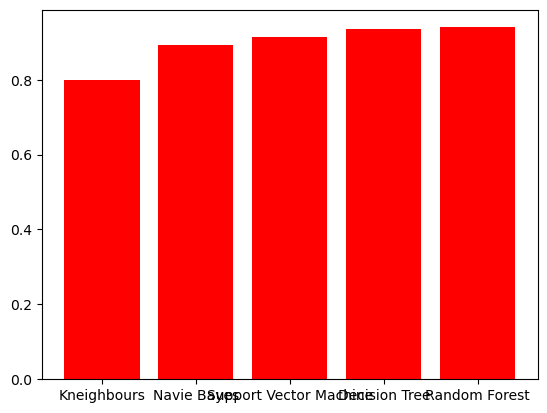

In [74]:
plt.bar(df9['Model Name'],df9['score'],color='red')

In [75]:
review=['very very bad memory']
rev=vec.transform(review)
pred=rf.predict(rev)
print('emotion: ',review[0])
print('prediction',pred[0])
if pred>0:
    print("positive")
elif pred==0:
    print('neutral')
else:
    print("negative")

emotion:  very very bad memory
prediction -1
negative
